# Introducción a las Redes Neuronales.

En esta libreta mostraremos el Teorema de Cybenko en acción mediante el funcionamento de una red neuronal. Esto sin el uso de librerias estándar.

## Ideas principales.
### Paso 1: Definir el problema. Estimar la función raiz cuadrada.

Por el Teorema de Cybenko sabemos que para la función $f(x)=\sqrt{x}$. Dado $\epsilon>0$, existe una red neuronal $\mathfrak{m}(\cdot,\Theta):\mathbb{R}\to\mathbb{R}$ tal que

$$
    |\mathfrak{m}(x,\Theta)-\sqrt{x}|<\epsilon
$$
Entonces construiremos una red neuronal que estime la función raiz cuadrada.

### Paso 2: Definir la red Neuronal. 
Recordando el teorema de Cybenko tenemos que 
$$
\mathfrak{m}(x,\Theta) = \sum_{n=1}^N c^n\sigma(w^nx+b^n),\Theta = \{(c^n,w^n,b^n)\}_{n=1}^N
$$
Para constuir la red neuronal debemos definir el numero de neuronas a utilizar. El Teorema de Cybenko nos dice que una capa oculta es suficiente.

### Paso 3: Función de Error.

Para entrenar la red neuronal usaremos un conjunto de datos de ejemplo $\mathcal{D}=\{(x_m,y_m)\}_{m=1}^M$ donde $M$ será la cantidad de datos. En este ejemplo usaremos la ejemplificaremos con el error cuadrático medio (MSELoss).

$$
    \ell(y,y') = (y-y')^2
$$
$$
    \Lambda(\Theta) = \dfrac{1}{M}\sum_{i=1}^{M}(y_m-\mathfrak{m}(x_m,\Theta))^{2}
$$

### Paso 4: Optimización.

El Teorema de Cybenko nos garantiza la existencia. Encontrar los parámetros, por lo general, consiste en resolver el problema de optimización.

$$
    \Theta^{*} = \argmin_{\Theta}\Lambda(\Theta)
$$

Como en este caso $\Theta\in\mathbb{R}^3$ podemos partir con el método de gradiente descendiente.

$$
    \Theta_{n+1} = \Theta_{n} - \alpha \nabla\Lambda(\Theta_n),
$$

donde $\alpha$ es la tasa de aprendizaje.


### Paso 5: Verificación.

Una vez la red haya terminado debemos verificar como actua en contraste con la función de interés. En general, se usan un conjunto de datos para entrenar y otro para verificar, en este caso podemos usar la función de interés de forma directa.


## Ejemplo. Estimar la función $f(x)=\sqrt{x}$

Para la prueba de código comenzaremos estimando la función raíz cuadrada. Esto lo haremos con una red con una neurona. Entonces iremos construyendo los elementos básicos.

### Red Neuronal $\mathfrak{m}(x,\Theta)$

In [194]:
import numpy as np

# Definimos la función de activación. El teorema nos dice que debe ser continua y de tipo sigmoidal.
def activation(x): 
    # Función Sigmoide
    y = 1 / (1 + np.exp(-x))
    return y

# Construimos la red neuronal. 
def model(x, theta, func=activation):
    # Se ve sencilla porque es una neurona.
    c = theta[0]
    w = theta[1]
    b = theta[2]
    v = w * x + b
    y = c * func(v)
    return y

### Función de Error $\Lambda(\Theta)$

In [195]:
# La función de error. El error cuadrático medio.
def MSE_nn(yv, xv, m, pars):
    M = len(yv)
    assert M == len(xv), "Revisa dimensiones"
    pred = np.array([m(x, pars) for x in xv])
    ell = (yv-pred) ** 2
    Lambda = M ** (-1) * ell.sum()
    return Lambda


### Optimización. Descenso Gradiente $\alpha$.

Para construirlo desde cero debemos recordar 2 elementos importantes. Sea $f:\mathbb{R}^d\to \mathbb{R}$ con $h$ suficientemente pequeña
$$
    \partial_{i}f=\dfrac{\partial f}{\partial x_i} \approx \dfrac{1}{h}(f(v+he_i)-f(v)),i=1,\ldots,d,
$$

$$
    \nabla f = (\partial_1f,\ldots,\partial_d f).
$$

Y la función a la que debemos sacar el gradiente 
$$
    \Lambda(\Theta) = \dfrac{1}{M}\sum_{i=1}^{M}(y_m-c\sigma(wx_m+b))^{2}
$$

In [196]:
import numpy as np


train_y = np.arange(0, 10)
train_x = train_y ** 2

# Funcion auxiliar para el algoritmo de gradiente descendente. 
## Requiere los datos de entrenamiento previamente definidos.
def error_learn(theta):
    y = MSE_nn(yv = train_y, xv = train_x, m=model, pars=theta)
    return y


def partial(func, rspct, v, tol=10**(-5)):
    d = len(v)
    assert 0 < rspct <= d, "Revisa la variable a derivar"
    e_i = np.array([1 if i==rspct else 0 for i in range(1, d+1)])
    df = func(v + e_i * tol) - func(v)
    pr = tol ** (-1) * df
    return pr


def gradient(func, v):
    d = len(v)
    # Usaremos la tolerancia definida en la derivada parcial.
    gd = np.array([partial(func, i + 1, v) for i in range(d)])
    return gd

**NOTA** Dejamos las derivadas parciales de la función de error por si quiere verificar los valores del gradiente.


\begin{align*}
\partial_{c}\Lambda & =\dfrac{2}{M}\sum^{M}_{i=1}\left(y_{m}-c\sigma(wx_{m}+b)\right)\left(-\sigma\left(wx_{m}+b\right)\right)\\
\partial_{w}\Lambda & =\dfrac{2}{M}\sum^{M}_{i=1}\left(y_{m}-c\sigma(wx_{m}+b)\right)\left(-c\partial_{w}\sigma\right),\\
\partial_{w}\Lambda & =\dfrac{2}{M}\sum^{M}_{i=1}\left(y_{m}-c\sigma(wx_{m}+b)\right)\left(-c\partial_{b}\sigma\right).
\end{align*}

Usando la sigmoide 
\begin{align*}
\sigma\left(wx_{m}+b\right) & =\dfrac{1}{1+\exp\left(-wx_{m}-b\right)}=\left(1+\exp\left(-wx_{m}-b\right)\right)^{-1}\\
\partial_{w}\sigma & =-\left(1+\exp\left(-wx_{m}-b\right)\right)^{-2}\left(-x_{m}\exp\left(-wx_{m}-b\right)\right)\\
\partial_{b}\sigma & =-\left(1+\exp\left(-wx_{m}-b\right)\right)^{-2}\left(-\exp\left(-wx_{m}-b\right)\right)
\end{align*}



In [197]:
def descent_gradent(func, theta0, epsilon, stop = 100, lr = 0.01):
    error = func(theta0)
    epochs = 0
    while error > epsilon:
        if epochs > stop:
            break
        thetan = theta0 - lr * gradient(error_learn, theta0)
        error = func(thetan)
        theta0 = thetan
        if epochs > 1000:
            print("Error:", error)
        epochs+=1
    return theta0


param_fit = descent_gradent(error_learn, [0.1,0.1,0.1], 0.001, lr=0.01)
param_fit

array([ 4.50410125,  0.14157597, -0.26996611])

### Verificación

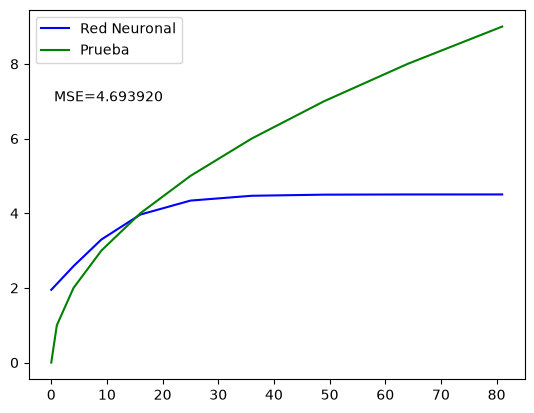

In [198]:
import matplotlib.pyplot as plt

def fitmodel(v):
    return model(v, param_fit)

predicted = [fitmodel(x) for x in train_x]
fig, ax = plt.subplots()
ax.plot(train_x, predicted, color="blue", label="Red Neuronal")
ax.plot(train_x, train_y, color="green", label="Prueba")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[0.5,7])
ax.legend()

## ¿Que pasó?

El error de los datos de prueba con la red neuronal es muy grande. Esto es normal y no tiene nada que ver con el Teorema de Cybenko.

Recapitulando, notemos que usamos la función de activación sigmoide
$$
    S(x)=\dfrac{1}{1+e^{-x}}.
$$

Se puede verificar que 
$$
    0\leq S(x)\leq 1,\forall x\in\mathbb{R}.
$$

Entonces es esperable, recordando que $\sqrt{x}$ no esta acotada, que fallará al aproximar.



In [199]:
def integ(x):
    c = 1/np.sqrt(2*np.pi)
    y = c * np.exp(-0.5 * x ** 2)
    return y

def goal(interval: tuple, N=100, func = integ):
    a,b = interval
    part = np.linspace(a,b, N)
    int_v = integ(part) * (b - a)
    return int_v.mean()

def distf(x):
    return goal((-10, x))

train_fx = np.linspace(-3, 3, 10)
train_fy = np.array([distf(x) for x in train_fx])

def error_learn(theta):
    y = MSE_nn(yv = train_fy, xv = train_fx, m=model, pars=theta)
    return y

param_fit = descent_gradent(error_learn, [0.1,0.1,0.1], 0.001, lr=0.01)
param_fit


array([0.50645424, 0.20582261, 0.14759317])

El error bajo de 4 a 0.18 al cambiar la función. Pero aun no es suficiente.

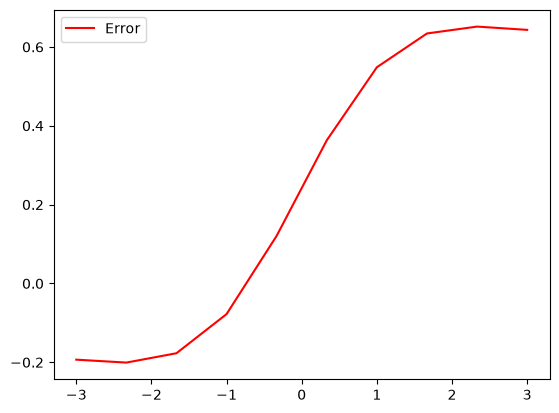

### Modificar la red neuronal.

En un problema real no podremos modificar la función de interés, por consecuencia tampoco la función de error. Pero podemos modificar la red neuronal para obtener mejores resultados.

#### Mas tiempo.

Muchas veces por la convergencia del algoritmo de optimización podemos requerir más iteraciones de las planeadas.

In [202]:

train_fx = np.linspace(-3, 3, 10)
train_fy = np.array([distf(x) for x in train_fx])

def error_learn(theta):
    y = MSE_nn(yv = train_fy, xv = train_fx, m=model, pars=theta)
    return y
# Lo reintentamos con más iteraciones
param_fit = descent_gradent(error_learn, [0.1,0.1,0.1], 0.001, stop=1_000)
param_fit


array([1.05275889, 0.93158385, 0.09647655])

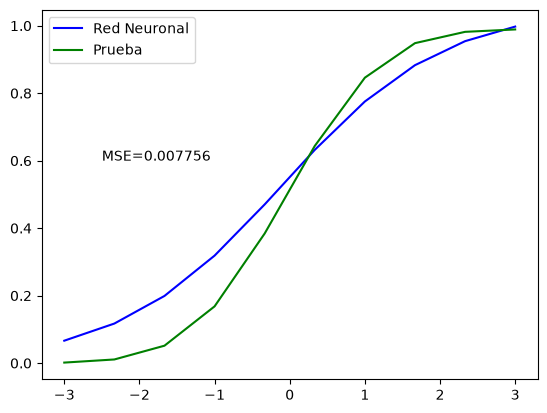

In [203]:
predicted = [fitmodel(x) for x in train_fx]
fig, ax = plt.subplots()
ax.plot(train_fx, predicted, color="blue", label="Red Neuronal")
ax.plot(train_fx, train_fy, color="green", label="Prueba")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[-2.5,0.6])
ax.legend()

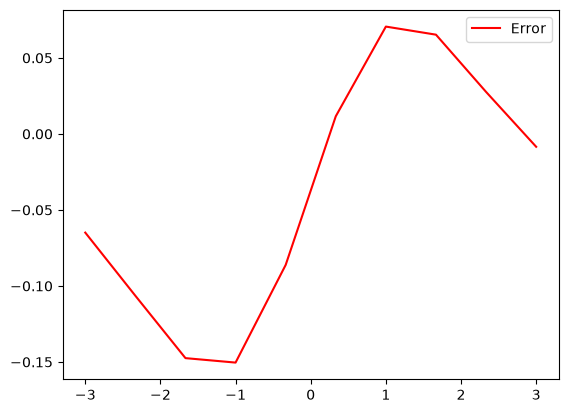

In [204]:
fig, ax = plt.subplots()
ax.plot(train_fx, train_fy-np.array(predicted), color="red", label="Error")
ax.legend()

#### Fijar una cota $\epsilon$.

Esto es exigir que el algoritmo se mantenga corriento hasta que el error sea menor que $\epsilon$, que es lo que garantiza Cybenko. Sin embargo, usar una cota nos quita el control del tiempo de ejecución y puede llevar a iteraciones infinitas o muy extensas.

In [205]:
train_fx = np.linspace(-3, 3, 10)
train_fy = np.array([distf(x) for x in train_fx])

def error_learn(theta):
    y = MSE_nn(yv = train_fy, xv = train_fx, m=model, pars=theta)
    return y
# Lo reintentamos con más iteraciones
param_fit = descent_gradent(error_learn, [0.1,0.1,0.1], epsilon=0.001, stop=np.inf)
param_fit


Error: 0.0077443019362305136
Error: 0.007733115283822423
Error: 0.007721954822378404
Error: 0.007710820465151951
Error: 0.007699712125778659
Error: 0.00768862971827369
Error: 0.007677573157029458
Error: 0.007666542356813863
Error: 0.007655537232767718
Error: 0.007644557700403006
Error: 0.0076336036756007855
Error: 0.007622675074609299
Error: 0.007611771814041309
Error: 0.007600893810872721
Error: 0.007590040982440341
Error: 0.007579213246439349
Error: 0.007568410520922312
Error: 0.007557632724296283
Error: 0.007546879775321458
Error: 0.007536151593108971
Error: 0.007525448097118953
Error: 0.007514769207158627
Error: 0.007504114843380279
Error: 0.007493484926279358
Error: 0.0074828793766932985
Error: 0.007472298115798474
Error: 0.007461741065109224
Error: 0.007451208146475425
Error: 0.007440699282081272
Error: 0.007430214394442983
Error: 0.007419753406407008
Error: 0.007409316241148516
Error: 0.007398902822169239
Error: 0.007388513073296328
Error: 0.0073781469186796735
Error: 0.00736780

array([ 1.04070745,  1.29737802, -0.04134346])

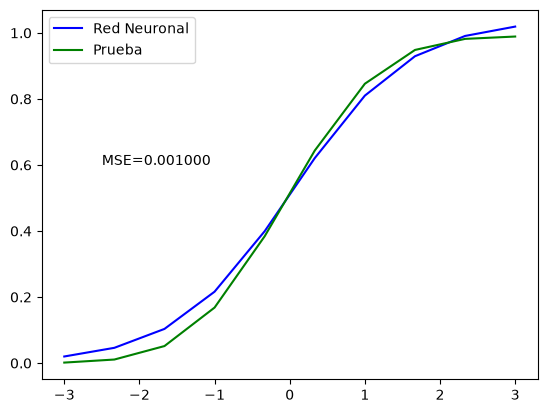

In [206]:
predicted = [fitmodel(x) for x in train_fx]
fig, ax = plt.subplots()
ax.plot(train_fx, predicted, color="blue", label="Red Neuronal")
ax.plot(train_fx, train_fy, color="green", label="Prueba")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[-2.5,0.6])
ax.legend()

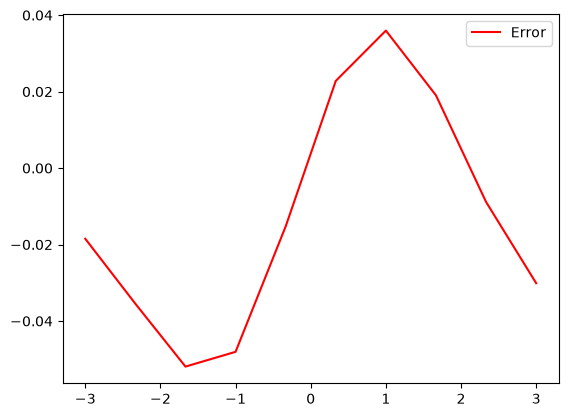

In [207]:
fig, ax = plt.subplots()
ax.plot(train_fx, train_fy-np.array(predicted), color="red", label="Error")
ax.legend()

In [210]:
train_fx = np.linspace(-3, 3, 10)
train_fy = np.array([distf(x) for x in train_fx])

def error_learn(theta):
    y = MSE_nn(yv = train_fy, xv = train_fx, m=model, pars=theta)
    return y
# Lo reintentamos con más iteraciones
param_fit = descent_gradent(error_learn, [0.1,0.1,0.1], epsilon=0.00001, stop=100_000)
param_fit

Error: 0.0077443019362305136
Error: 0.007733115283822423
Error: 0.007721954822378404
Error: 0.007710820465151951
Error: 0.007699712125778659
Error: 0.00768862971827369
Error: 0.007677573157029458
Error: 0.007666542356813863
Error: 0.007655537232767718
Error: 0.007644557700403006
Error: 0.0076336036756007855
Error: 0.007622675074609299
Error: 0.007611771814041309
Error: 0.007600893810872721
Error: 0.007590040982440341
Error: 0.007579213246439349
Error: 0.007568410520922312
Error: 0.007557632724296283
Error: 0.007546879775321458
Error: 0.007536151593108971
Error: 0.007525448097118953
Error: 0.007514769207158627
Error: 0.007504114843380279
Error: 0.007493484926279358
Error: 0.0074828793766932985
Error: 0.007472298115798474
Error: 0.007461741065109224
Error: 0.007451208146475425
Error: 0.007440699282081272
Error: 0.007430214394442983
Error: 0.007419753406407008
Error: 0.007409316241148516
Error: 0.007398902822169239
Error: 0.007388513073296328
Error: 0.0073781469186796735
Error: 0.00736780

array([0.99767627, 1.68160813, 0.06155491])

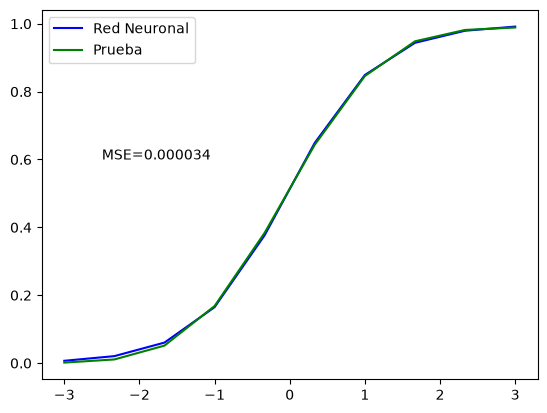

In [211]:
predicted = [fitmodel(x) for x in train_fx]
fig, ax = plt.subplots()
ax.plot(train_fx, predicted, color="blue", label="Red Neuronal")
ax.plot(train_fx, train_fy, color="green", label="Prueba")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[-2.5,0.6])
ax.legend()